# W11B · 지시변수의 세 응용을 계산하고 수정하기

회귀분석의 이해 · 2026-11-10 · 주교재6.5–6.7·장말·SAS/R 대응. 자체9개 예, 스키40분기, 교육비150행을 구별합니다. 예상→한 행 계산→실제 함수 수정→결과 해석을 남기세요. 새 성적 반영 과제나 제출 기한은 없습니다.

[온라인 R](https://lunalab-ai.github.io/regre/w11b.html) · [코드를 수정하는 앱](https://lunalab-ai.github.io/regre/apps/w11b/edit/index.html) · [R/QMD](https://github.com/lunalab-ai/regre/tree/2026-fall-w11b/labs/student/w11b)

함수 본문은 src의 실제 정의에서 자동 추출한 동일 초기 코드입니다. 입력·출력과 각 줄의 역할을 본문에서 읽고 직접 수정합니다. 준비 파일은 한 번 불러오며 이후 편집을 몰래 덮어쓰지 않습니다. 모형을 바꿨다면 해당 적합과 이후 셀도 다시 실행하세요.

B편입니다. 다른 노트북 없이 준비부터 독립 실행합니다.

In [ ]:
# Bundled inputs first. A fixed-tag download is used only when no local copy exists.
tag <- "2026-fall-w11b"
local_dirs <- c("data","labs/student/w11b/data","../../labs/student/w11b/data","../../../labs/student/w11b/data")
found <- local_dirs[file.exists(file.path(local_dirs,"indicator-applications-w11b.R"))]
cache_root <- Sys.getenv("REGRE_CACHE_DIR",unset=file.path(path.expand("~"),".cache","regre"))
data_dir <- if(length(found)) found[1] else file.path(cache_root,tag)
dir.create(data_dir,recursive=TRUE,showWarnings=FALSE)
expected <- c("categorical-trace-w11b.R"="cd201e03f0de484b2ee9bb71b7d56e24","indicator-applications-w11b.R"="dcbf19df1dfa8c0618b4577fe649aec5","ski-sales-w11b.csv"="0ccf5e3ffa6992bdb40ba2977addd87c","education-w11b.csv"="8ed5c621f5a02c46ca4654c81d3644d0","fertilizer-w11b.csv"="d9adb09eac8823b7a3d21b0a84b757df")
options(timeout=120)
for(name in names(expected)) {
 target <- file.path(data_dir,name)
 if(!file.exists(target)) {
  status <- download.file(paste0("https://raw.githubusercontent.com/lunalab-ai/regre/",tag,"/labs/student/w11b/data/",name),target,mode="wb")
  if(status!=0) stop("Download failed: check the connection and rerun this preparation cell.")
  cat(name,": fixed-tag download\n")
 } else cat(name,": bundled/cache file\n")
 if(unname(tools::md5sum(target))!=expected[[name]])
  stop("Input bytes differ. Preserve your edited copy and use a fresh data folder/cache.")
}
source(file.path(data_dir,"categorical-trace-w11b.R"),encoding="UTF-8")
source(file.path(data_dir,"indicator-applications-w11b.R"),encoding="UTF-8")
ski_raw <- read.csv(file.path(data_dir,"ski-sales-w11b.csv"))
edu_raw <- read.csv(file.path(data_dir,"education-w11b.csv"))
corn <- read.csv(file.path(data_dir,"fertilizer-w11b.csv"))
toy <- data.frame(source_row=1:9,y=c(4,5,6,6,7,8,8,9,10),Group=factor(rep(c("A","B","C"),each=3),levels=c("C","A","B")))
contrasts(toy$Group) <- contr.treatment(levels(toy$Group),base=1)
ski <- ia_quarter_prepare(ski_raw)
edu <- ia_year_prepare(edu_raw)
stopifnot(nrow(ski)==40,nrow(edu)==150,nrow(corn)==40,all(table(ski$Quarter)==10),all(table(edu$YearGroup)==50))
cat("W11B_DATA_READY: own9 / Ski40 / Education150 / Corn40.\n")
print(R.version.string)

## E07 · 150행을 두 연도 지시변수와 곱항으로 펼치기

한 행은 주×연도입니다. 같은 주의 세 연도 관측을 다른 주150개로 오해하지 않습니다. 기준1975에서는 두 연도 지시변수가0입니다. X2/X3는 인구1000명당 수입니다.

![150행을 두 연도 지시변수와 곱항으로 펼치기](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11b/course/notion/w11b/images/w11b-f12.png)
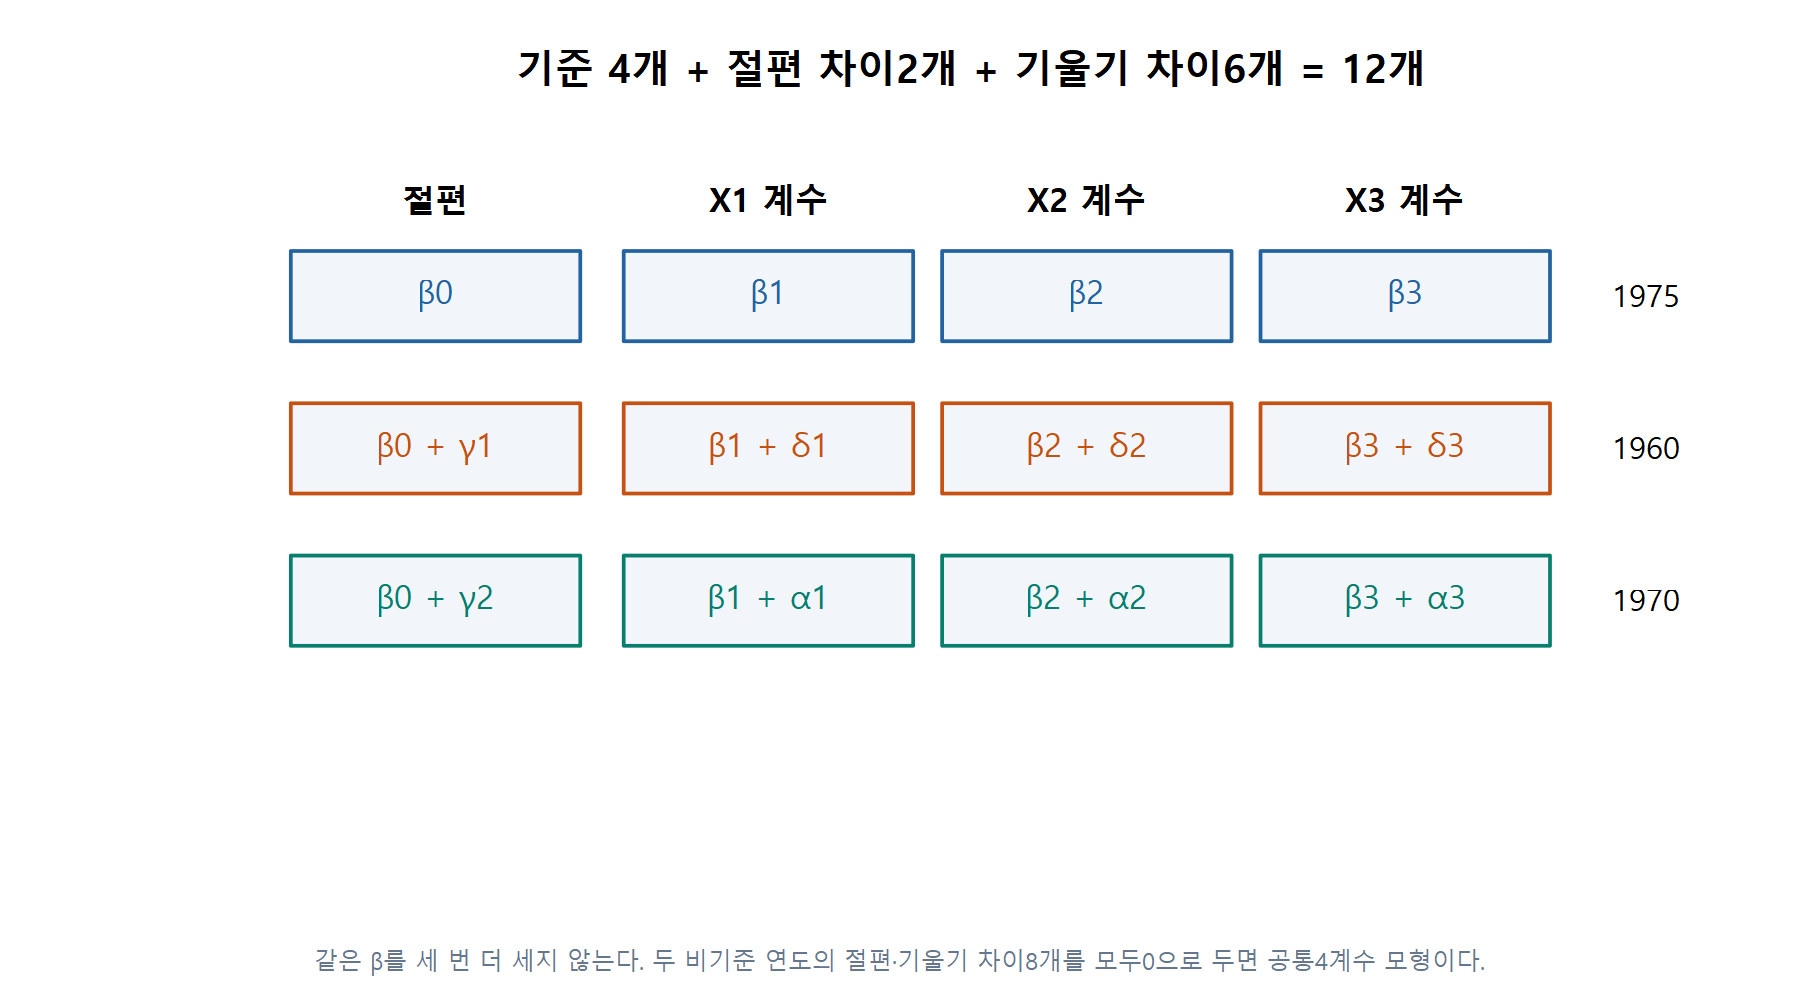

In [ ]:
ia_year_prepare <- function(data, reference=1975L) {
  d <- ia_rows(data,c("STATE","Y","X1","X2","X3","Year"))
  nums <- c("Y","X1","X2","X3","Year")
  if (!all(vapply(d[nums],is.numeric,logical(1))) || any(!is.finite(as.matrix(d[nums]))))
    stop("Use complete finite numeric Y/X1/X2/X3/Year.")
  d$STATE <- trimws(as.character(d$STATE))
  years <- c(1960L,1970L,1975L)
  if (any(!nzchar(d$STATE)) || anyDuplicated(paste(d$STATE,d$Year)) ||
      !setequal(unique(d$Year),years)) stop("Need unique STATE-Year keys for 1960/1970/1975.")
  if (length(reference)!=1L || !reference %in% years) stop("Choose a source year as reference.")
  d$YearGroup <- factor(d$Year,levels=c(reference,setdiff(years,reference)))
  contrasts(d$YearGroup) <- contr.treatment(levels(d$YearGroup),base=1)
  d
}
edu <- ia_year_prepare(edu_raw,1975)
print(edu[1:4,c("source_row","STATE","Year","Y","X1","X2","X3","YearGroup")])

## E08 · 직접 수정할 모형 함수와 실제 호출

ia_full_formula의 *를 +로 바꾸면 연도별 기울기 차이를 없앱니다. ia_year_models는 전달받은 바로 그 함수 객체를 호출합니다. 이후에 source를 다시 실행하여 수정 내용을 덮어쓰지 않습니다.

![직접 수정할 모형 함수와 실제 호출](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11b/course/notion/w11b/images/w11b-f12.png)
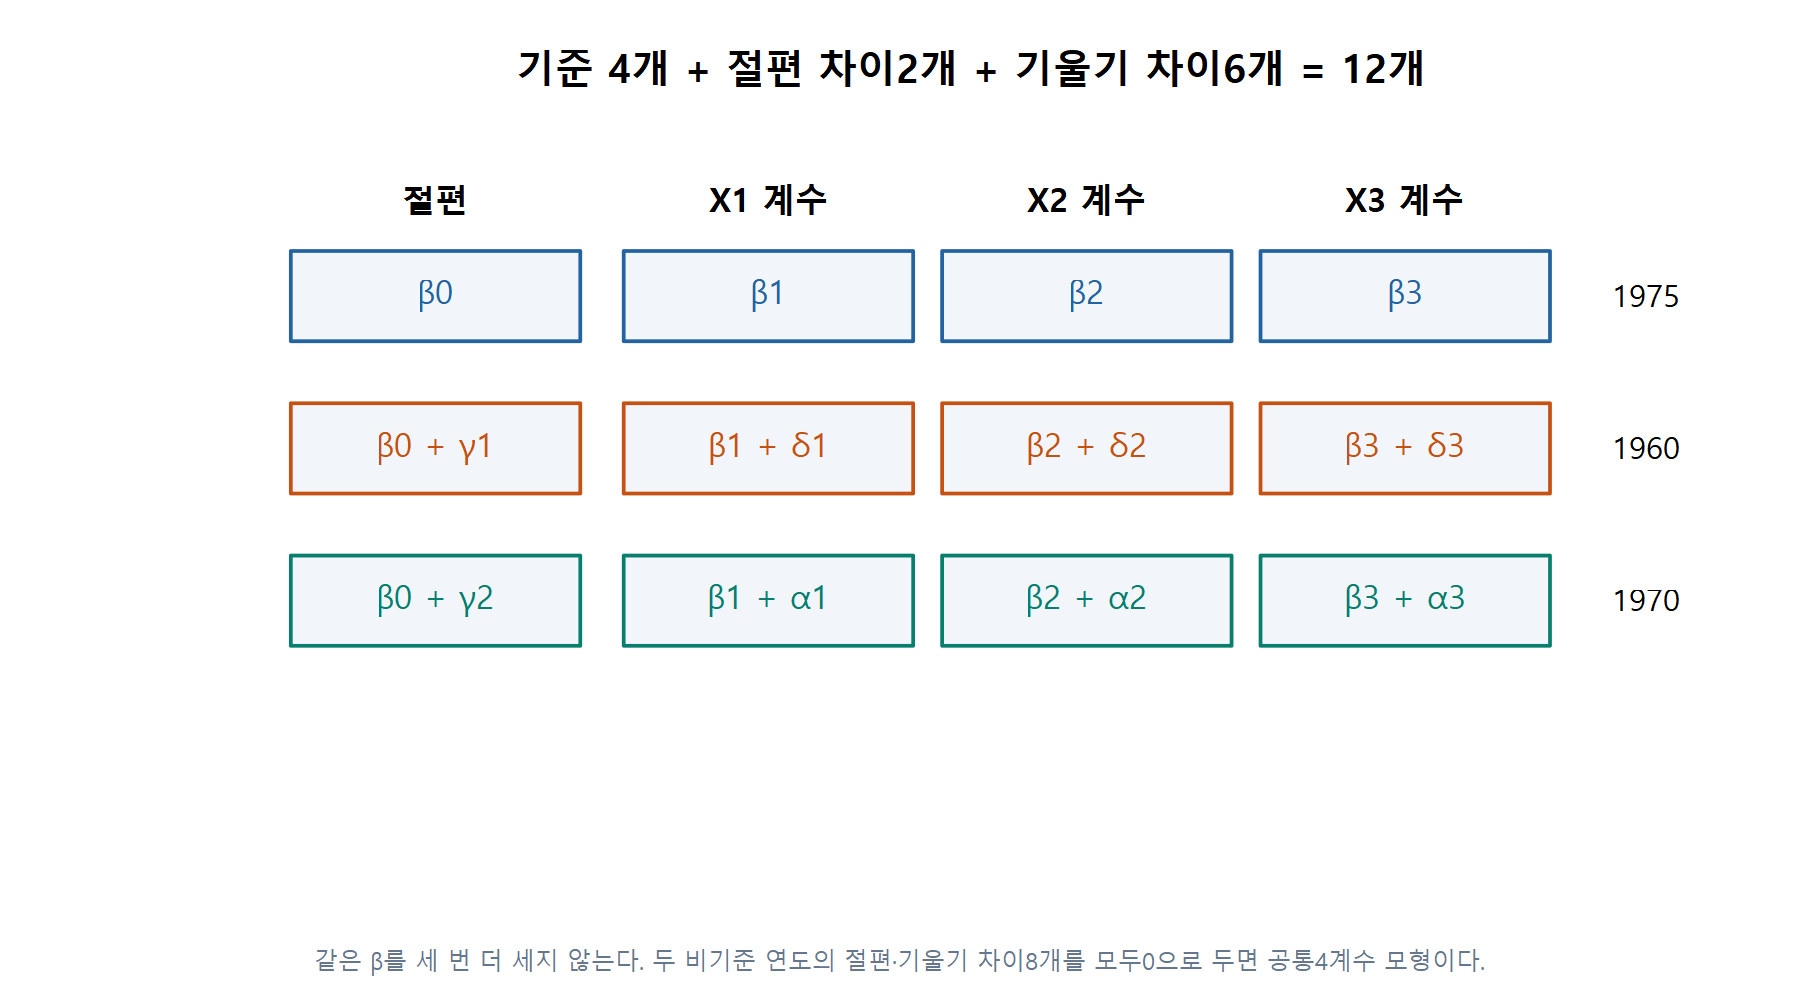

In [ ]:
ia_full_formula <- function() {
  Y ~ (X1 + X2 + X3) * YearGroup
}
ia_year_models <- function(data, formula_fn=ia_full_formula) {
  if (!is.function(formula_fn)) stop("formula_fn must be the actual function you edited.")
  d <- ia_rows(data,c("Y","X1","X2","X3","YearGroup"))
  if (!is.factor(d$YearGroup)) stop("Use prepared categorical YearGroup.")
  models <- list(common=lm(Y~X1+X2+X3,d,na.action=na.fail),
    intercept=lm(Y~X1+X2+X3+YearGroup,d,na.action=na.fail),
    full=lm(formula_fn(),d,na.action=na.fail))
  invisible(lapply(models,cat_check_fit))
  cat_check_pair(models$common,models$full)
  models
}
year_models <- ia_year_models(edu,ia_full_formula)
print(vapply(year_models,function(f) f$rank,integer(1)))
print(model.matrix(year_models$full)[1:4,]);print(coef(year_models$full))

## E09 · 4개에서12개 계수: 새 제약8개와 잔차 자유도138

아래 두 실제 함수는 다른 창의 API 설명이 아닙니다. QR와 SSE-F 계산을 본문에서 읽고 수정할 수 있습니다. 완전모형의 계수 수와 잔차 자유도를 실제 적합에서 읽습니다.

![4개에서12개 계수: 새 제약8개와 잔차 자유도138](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11b/course/notion/w11b/images/w11b-f13.png)
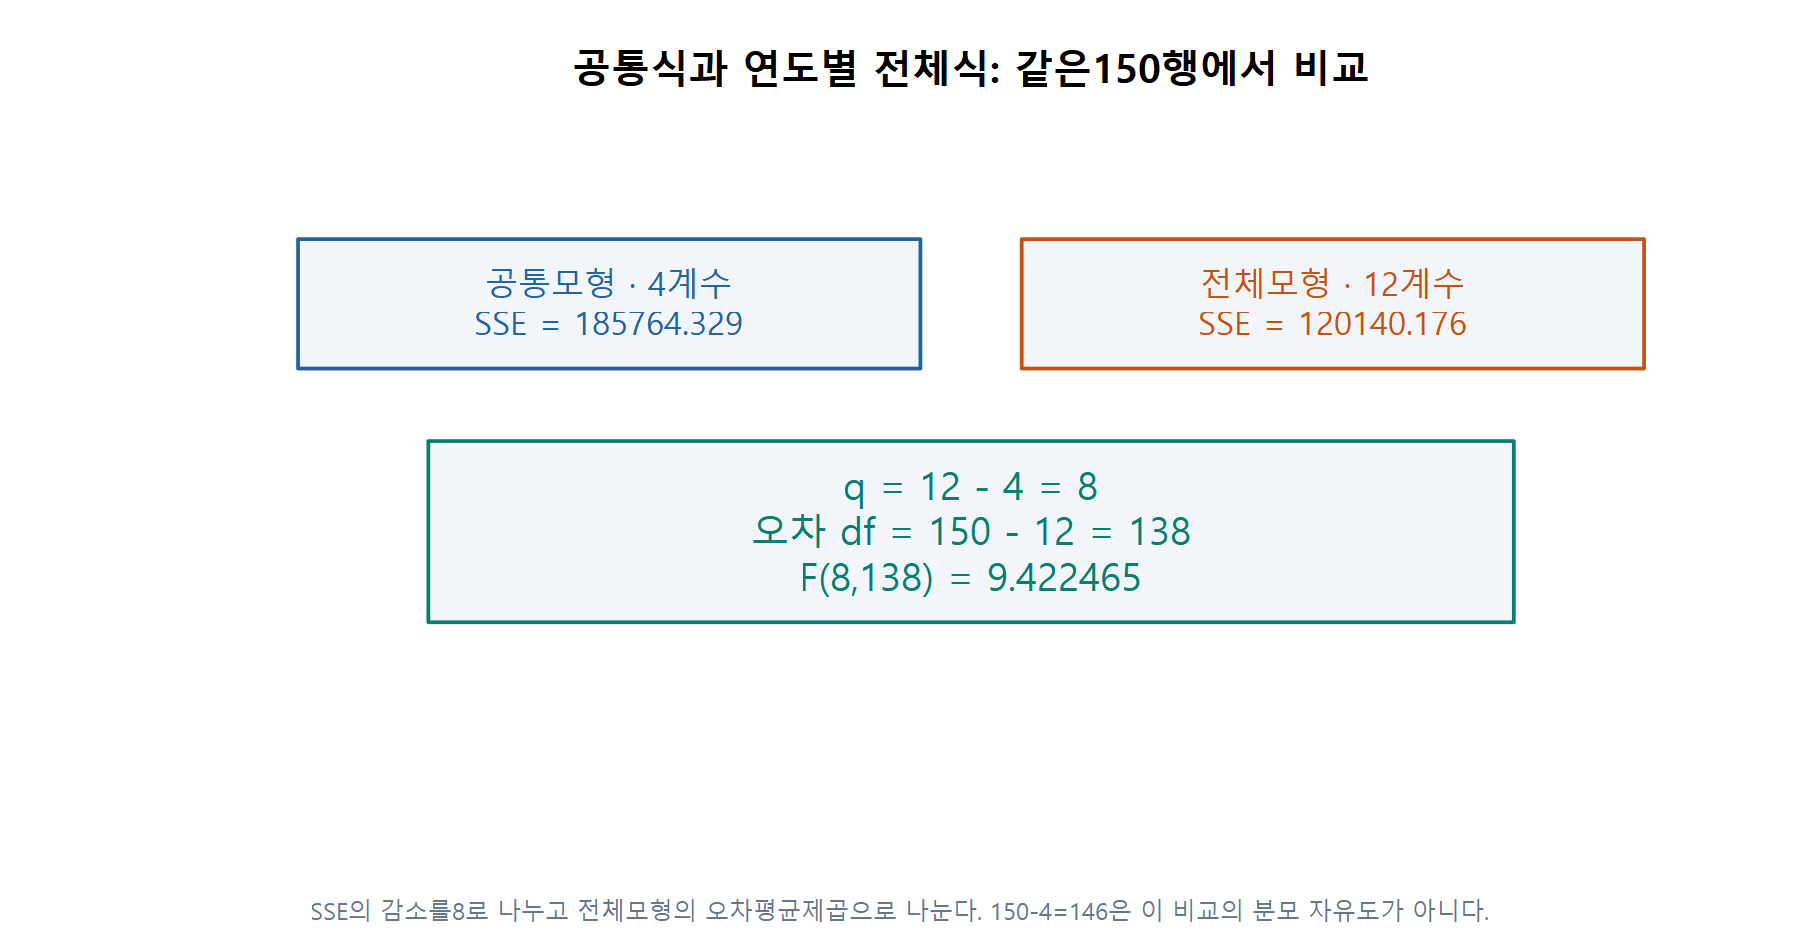

In [ ]:
cat_fit_trace <- function(fit) {
  frame <- cat_check_fit(fit)
  design <- model.matrix(fit)
  observed <- model.response(frame)
  beta <- qr.coef(qr(design),observed)
  fitted <- drop(design %*% beta)
  residual <- observed-fitted
  squared <- residual^2
  rows <- data.frame(source_row=rownames(design),observed=unname(observed),
    fitted=unname(fitted),residual=unname(residual),squared=unname(squared),
    cumulative=cumsum(unname(squared)),row.names=NULL)
  list(design=design,coefficients=beta,rows=rows,
    SSE=sum(squared),n=nrow(design),k=ncol(design),df=df.residual(fit))
}
cat_nested_trace <- function(reduced, full, tolerance=1e-9) {
  checked <- cat_check_pair(reduced,full,tolerance)
  SSE_reduced <- sum(residuals(reduced)^2)
  SSE_full <- sum(residuals(full)^2)
  if (SSE_full<=0 ||
      SSE_reduced<SSE_full-tolerance*max(1,SSE_reduced))
    stop("F needs positive full-model residual variance and a valid nested SSE.")
  q <- checked$q
  df_full <- checked$df_full
  # A tiny negative difference can only be numerical roundoff for nested OLS.
  increase <- max(0,SSE_reduced-SSE_full)
  F <- (increase/q)/(SSE_full/df_full)
  data.frame(n=checked$n,k_reduced=reduced$rank,k_full=full$rank,q=q,
    df_full=df_full,SSE_reduced=SSE_reduced,SSE_full=SSE_full,
    F=F,p=pf(F,q,df_full,lower.tail=FALSE))
}
year_trace <- cat_fit_trace(year_models$full)
year_test <- cat_nested_trace(year_models$common,year_models$full)
print(year_trace$rows[1:6,]);print(year_test)
print(anova(year_models$common,year_models$full))
one_state <- edu[1,,drop=FALSE]
one_state$YearGroup <- factor(as.character(one_state$YearGroup),levels=levels(edu$YearGroup))
print(cat_row_trace(year_models$full,one_state))

## E10 · 기준 변경의 불변성과 관측 범위

1975를1960으로 바꾸는 것은 같은 모형의 표현 변경입니다. 반면 *를 +로 바꾸는 것은 다른 제약입니다. 세 연도의 X1범위가 공통으로 겹치지 않으므로 같은 소득에서의 모든 연도 비교를 관측 범위 안의 비교라고 부르지 않습니다.

![기준 변경의 불변성과 관측 범위](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11b/course/notion/w11b/images/w11b-f14.png)
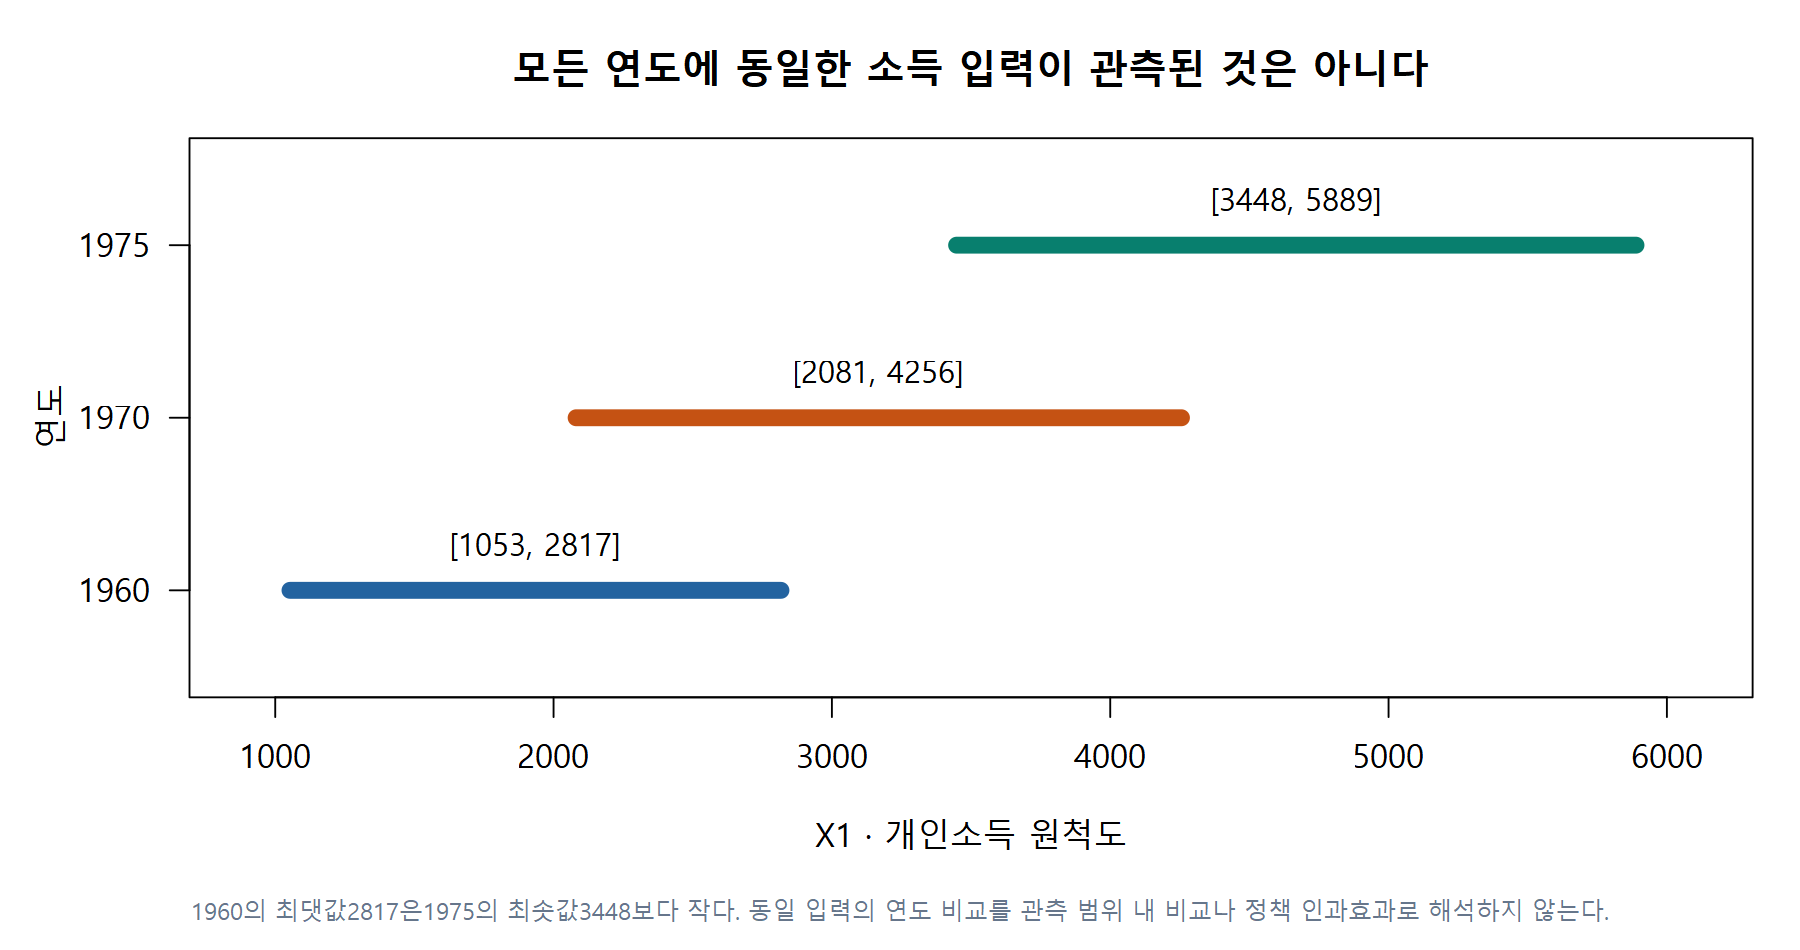

In [ ]:
edu_ref1960 <- ia_year_prepare(edu_raw,1960)
other_reference <- ia_year_models(edu_ref1960,ia_full_formula)
print(max(abs(fitted(year_models$full)-fitted(other_reference$full))))
print(aggregate(X1~YearGroup,edu,range))
plot(fitted(year_models$full),edu$Y,col=as.integer(edu$YearGroup),pch=19,xlab="Fitted Y (original scale)",ylab="Observed Y (original scale)")
abline(0,1,lty=2)

## E11 · 수정 코드에서 앱·CSV·R 저장본으로

아래 student_formula를 고치고 실행하면 실제 적합이 바뀝니다. 앱은 별도 실행환경입니다. 같은 함수를 앱 편집기에도 반영하고 Run을 누르세요. 앱에서 현재 표 CSV와 독립 실행 R을 내려받아 새 R세션에서 같은 값을 확인합니다.

![수정 코드에서 앱·CSV·R 저장본으로](https://raw.githubusercontent.com/lunalab-ai/regre/2026-fall-w11b/course/notion/w11b/images/w11b-f15.png)
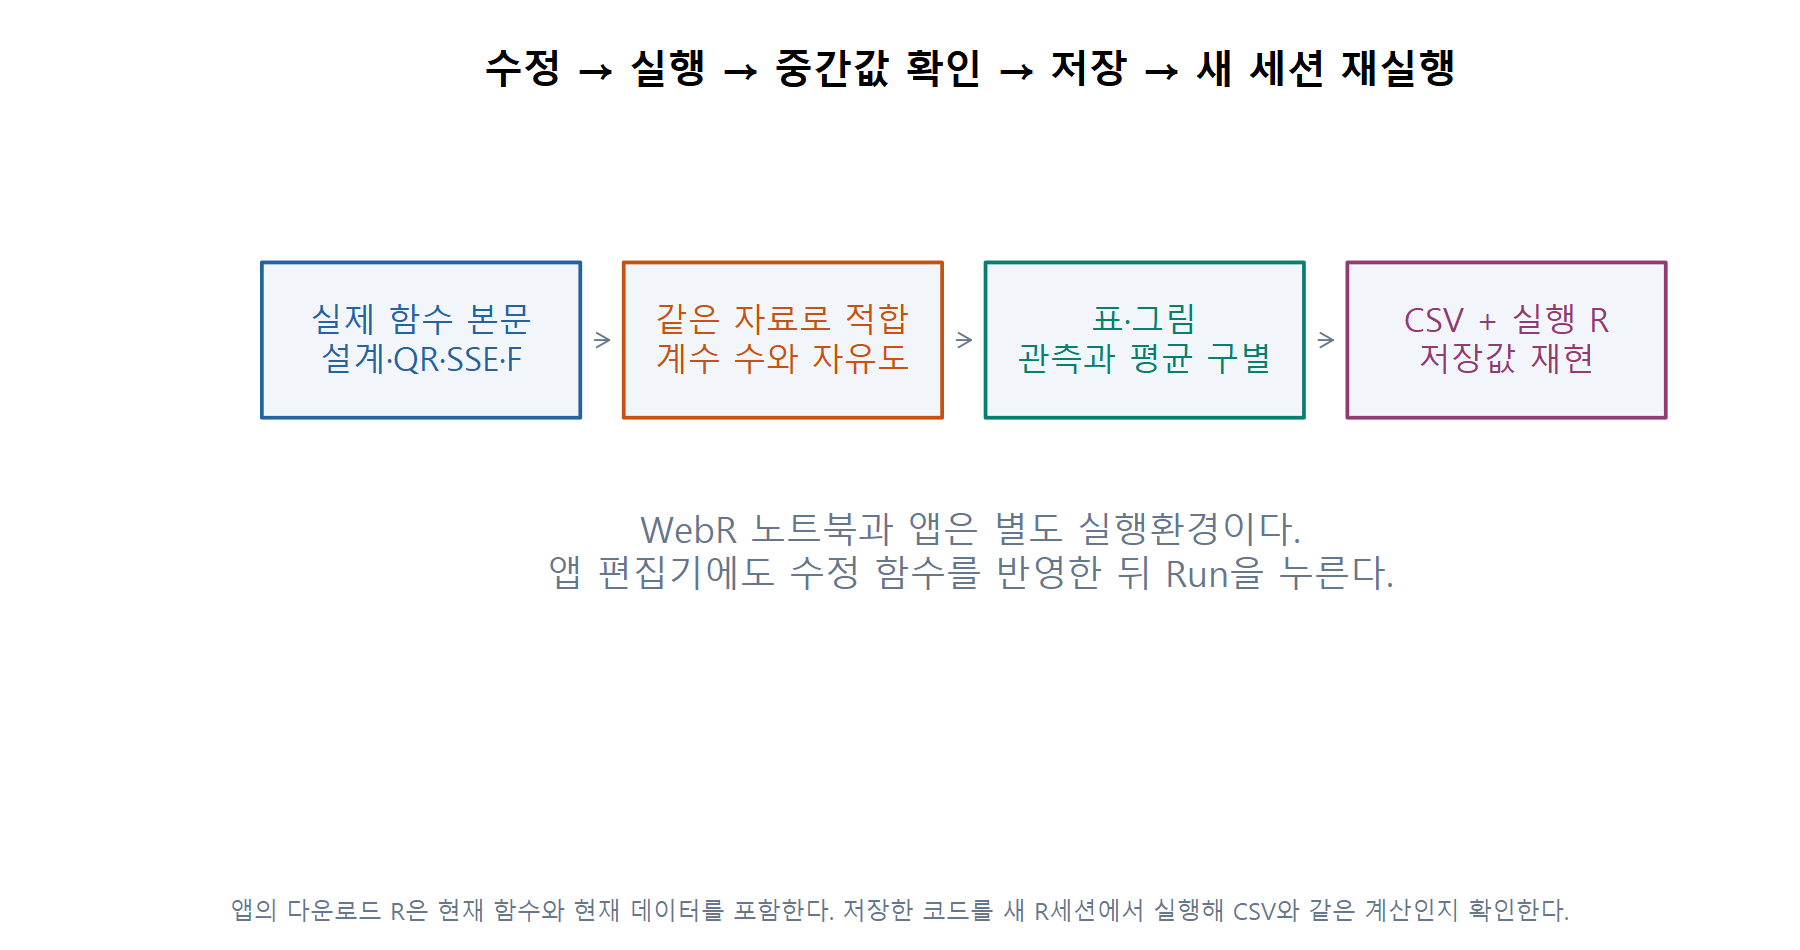

In [ ]:
student_formula <- function() {
 Y ~ (X1 + X2 + X3) * YearGroup
}
my_models <- ia_year_models(edu,student_formula)
print(cat_nested_trace(my_models$common,my_models$full))

### L05 · 교육비 F 분모 오류 찾기

공통모형4계수와 전체모형12계수를 비교할 때 q와 분모 자유도를 적으세요. SSE전체/(150−4)를 분모로 쓴 코드를 왜 고쳐야 하나요?

힌트: F의 오차 크기는 완전모형으로 추정합니다.

자가 점검: 기준1975의4개 계수와1960/1970의 추가8개를 구별합니다.

In [ ]:
my_L05_prediction <- NA_real_
my_L05_reason <- ""

### L06 · 수정 함수를 실제 앱에 연결

student_formula의 *를 +로 바꾼 사본을 실행하세요. 앱 편집기에도 같은 함수를 반영하고 Run 후 표·그림·CSV·독립 실행 R을 저장하세요. 새 R세션에서 저장본을 재실행하세요.

힌트: 노트북과 앱은 별도 실행환경입니다.

자가 점검: 표시 제목뿐 아니라 실제 열·계수 수·F·다운로드 값이 바뀌어야 합니다.

In [ ]:
my_L06_prediction <- NA_real_
my_L06_reason <- ""

### L09 · 선택: 다섯 제품으로 전이

제품5종과 연속 지름 하나로 작업시간을 설명합니다. 절편·기울기를 모두 제품별로 허용하면 계수는 몇 개인가요? 59행에서 공통직선과 비교할 q·잔차df를 적으세요.

힌트: 기준제품2개 + 나머지4제품의 절편/기울기 차이를 셉니다.

자가 점검: 제약 수와 집단 수를 혼동하지 않습니다.

In [ ]:
my_L09_prediction <- NA_real_
my_L09_reason <- ""

### 실제 입력 검사·행 기여 · cat_check_fit

In [ ]:
cat_check_fit <- function(fit) {
  if (!inherits(fit,"lm") || !is.data.frame(fit$model))
    stop("Use a standard lm with its complete model frame retained.")
  frame <- fit$model
  design <- model.matrix(fit)
  y <- model.response(frame)
  if (!is.numeric(y) || is.matrix(y) || any(!is.finite(y)) ||
      any(!is.finite(design)) || !is.null(model.weights(frame)) ||
      !is.null(model.offset(frame)) || fit$rank!=ncol(design) ||
      df.residual(fit)<1L || any(!is.finite(coef(fit))))
    stop("Require finite, unweighted, no-offset, full-rank univariate OLS with residual df.")
  frame
}

### 실제 입력 검사·행 기여 · cat_check_pair

In [ ]:
cat_check_pair <- function(reduced, full, tolerance=1e-9) {
  r <- cat_check_fit(reduced)
  f <- cat_check_fit(full)
  if (!identical(rownames(r),rownames(f)) ||
      !isTRUE(all.equal(model.response(r),model.response(f),tolerance=0)))
    stop("Compare the same response and identical observations in identical order.")
  xr <- model.matrix(reduced)
  xf <- model.matrix(full)
  if (length(tolerance)!=1L || !is.numeric(tolerance) ||
      !is.finite(tolerance) || tolerance<=0) stop("Use positive finite tolerance.")
  q <- full$rank-reduced$rank
  if (q<=0 || max(abs(qr.resid(qr(xf),xr)))>tolerance*max(1,abs(xr)))
    stop("Reduced design must be nested in full design with fewer parameters.")
  list(n=nrow(f),q=q,df_full=df.residual(full))
}

### 실제 입력 검사·행 기여 · cat_row_trace

In [ ]:
cat_row_trace <- function(fit, newdata) {
  cat_check_fit(fit)
  if (!is.data.frame(newdata) || nrow(newdata)<1L)
    stop("newdata must contain at least one complete observation.")
  term <- delete.response(terms(fit))
  frame <- model.frame(term,newdata,na.action=na.fail,xlev=fit$xlevels)
  design <- model.matrix(term,frame,contrasts.arg=fit$contrasts)
  beta <- coef(fit)
  if (!identical(colnames(design),names(beta)) || any(!is.finite(design)))
    stop("New rows must use the fitted columns, factor levels and finite values.")
  contribution <- sweep(design,2,beta,"*")
  data.frame(row=rep(seq_len(nrow(design)),each=ncol(design)),
    term=rep(colnames(design),times=nrow(design)),
    value=as.vector(t(design)),coefficient=rep(unname(beta),times=nrow(design)),
    contribution=as.vector(t(contribution)),row.names=NULL)
}

In [ ]:
stopifnot(nrow(edu)==150,year_models$common$rank==4,year_models$intercept$rank==6,year_models$full$rank==12,
 year_test$q==8,year_test$df_full==138,abs(year_test$F-anova(year_models$common,year_models$full)$F[2])<1e-8,
 max(abs(year_trace$rows$fitted-fitted(year_models$full)))<1e-7,
 max(abs(fitted(year_models$full)-fitted(other_reference$full)))<1e-7)
cat("W11B_STABILITY_RUNTIME_PASS: source calculations, not exercise completion\n")